In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

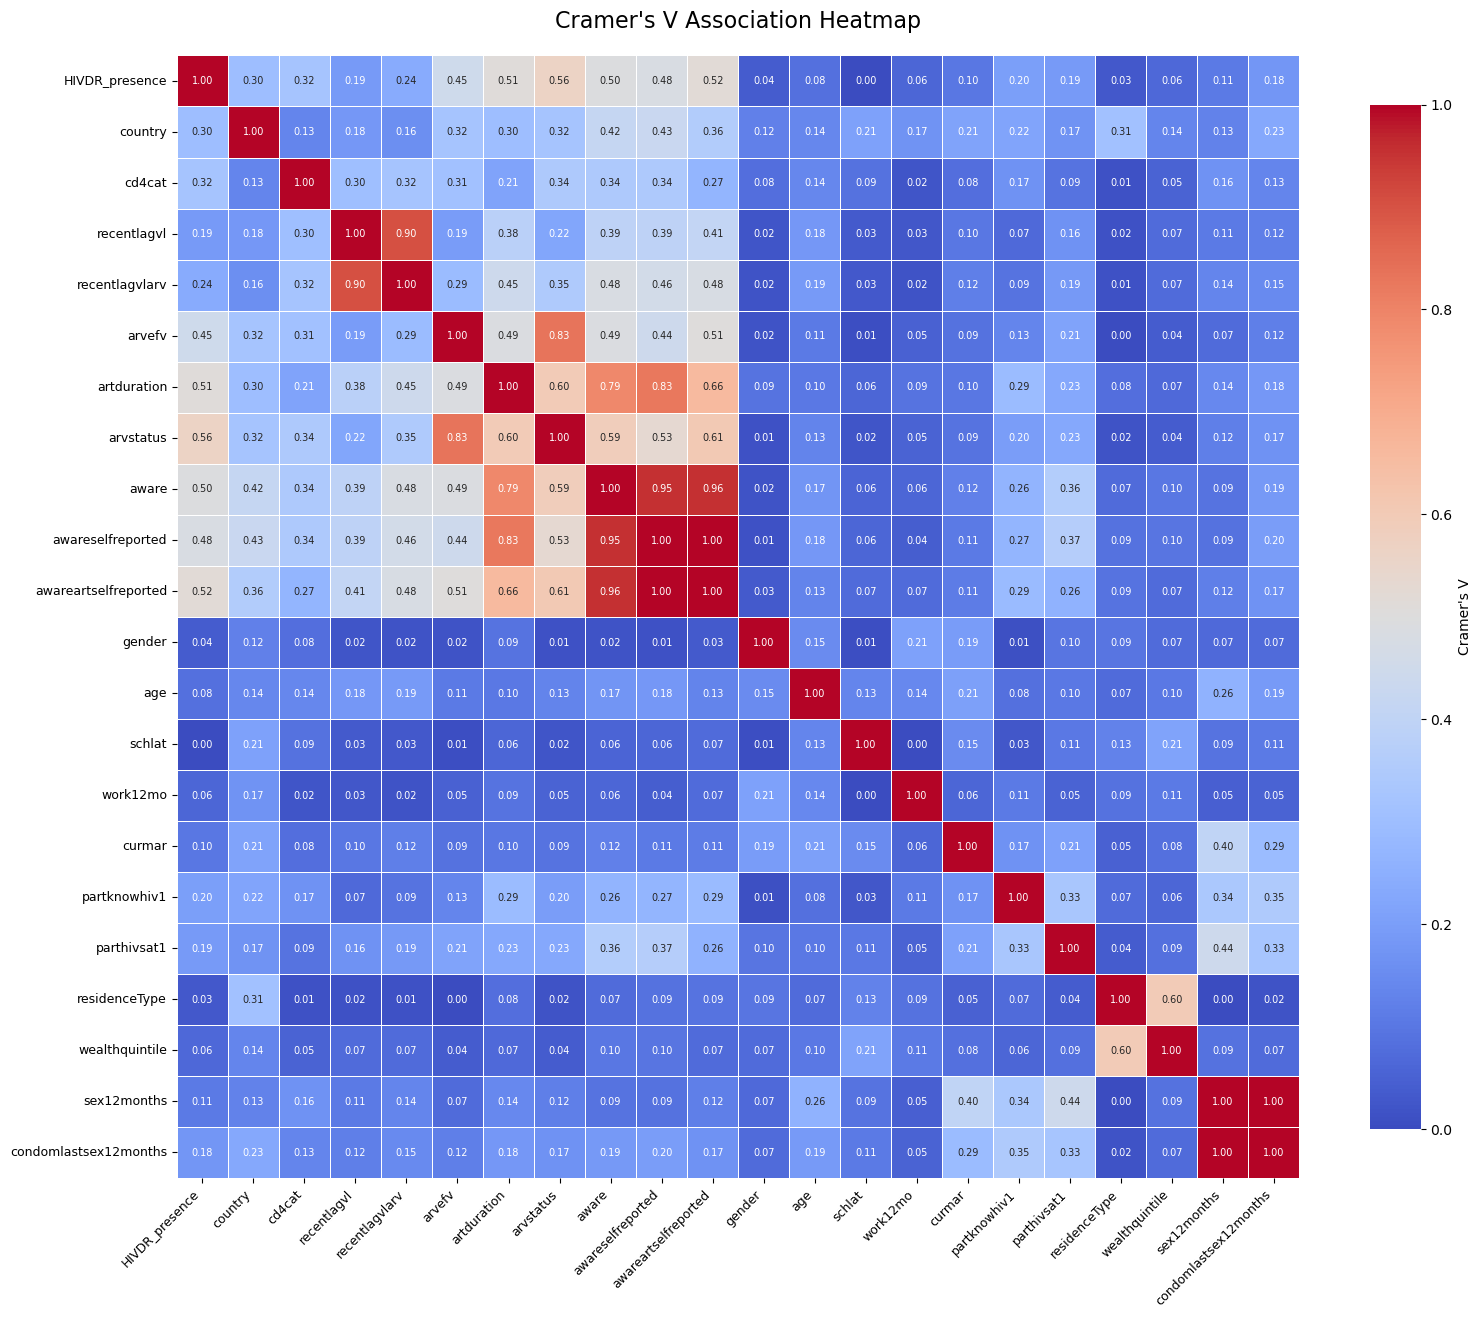

Heatmap saved as 'Cramers_V_Association_Heatmap.png'

After removing highly associated features, the dataset has 1191 rows and 17 columns.


In [2]:
df = pd.read_csv('Chi-square Analysis Data_Final.csv', low_memory=False)

#Cramer's V calculation function
def cramers_v(x, y):
    """Calculate Cramer's V statistic for categorical-categorical association."""
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    min_dim = min(confusion_matrix.shape) - 1
    
    if min_dim == 0:
        return 0
    cramers_v = np.sqrt(chi2 / (n * min_dim))
    return cramers_v

def calculate_cramers_v_matrix(df, columns):
    """Calculate Cramer's V for all pairs of categorical variables."""
    n_cols = len(columns)
    cramers_matrix = np.zeros((n_cols, n_cols))
    
    for i, col1 in enumerate(columns):
        for j, col2 in enumerate(columns):
            if i == j:
                cramers_matrix[i, j] = 1.0
            else:
                valid_idx = df[[col1, col2]].dropna().index
                if len(valid_idx) > 0:
                    cramers_matrix[i, j] = cramers_v(
                        df.loc[valid_idx, col1], 
                        df.loc[valid_idx, col2]
                    )
                else:
                    cramers_matrix[i, j] = 0
    
    cramers_df = pd.DataFrame(cramers_matrix, index=columns, columns=columns)
    return cramers_df

# Combining all variables
dependent_var = 'HIVDR_presence'

independent_vars = [
    'country',
    'cd4cat',
    'recentlagvl',
    'recentlagvlarv',
    'arvefv',
    'artduration',
    'arvstatus',
    'aware',
    'awareselfreported',
    'awareartselfreported',
    'gender',
    'age',
    'schlat',
    'work12mo',
    'curmar',
    'partknowhiv1',
    'parthivsat1',
    'residenceType',
    'wealthquintile',
    'sex12months',
    'condomlastsex12months'
]
all_variables = [dependent_var] + independent_vars

# Calculating Cramer's V matrix
cramers_matrix = calculate_cramers_v_matrix(df, all_variables)

# Creating the heatmap
plt.figure(figsize=(16, 14))

sns.heatmap(cramers_matrix, 
            annot=True,
            fmt='.2f',
            cmap='coolwarm',
            center=0.5,
            vmin=0, 
            vmax=1,
            square=True,
            linewidths=0.5,
            linecolor='white',
            cbar_kws={'label': "Cramer's V", 'shrink': 0.8},
            annot_kws={'fontsize': 7})

plt.title("Cramer's V Association Heatmap", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig('Cramers_V_Association_Heatmap.png', dpi=300, bbox_inches='tight')
plt.show()
print("Heatmap saved as 'Cramers_V_Association_Heatmap.png'")
print()

# Dropping features highly associated with others (Cramér’s V ≥ 0.80)
features_to_drop = ['sex12months', 'awareselfreported', 'aware', 'arvefv', 'recentlagvl']
df = df.drop(columns=features_to_drop)
rows, cols = df.shape
print(f"After removing highly associated features, the dataset has {rows} rows and {cols} columns.")

In [3]:
df.to_csv('Feature Selection Data_Final.csv', index=False, encoding='utf-8-sig')